# Jacobi and Gauss-Seidel iterative methods

Solving a linear system $A\mathbf{x} = \mathbf{b}$ by successive approximations: theory, implementation, and a worked example.
\
Split the matrix as $A = D + L + U$, where $D$ is the diagonal, $L$ the strictly lower part and $U$ the strictly upper part of $A$.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Jacobi Method


**Jacobi** uses only values from the previous iteration:

$$x_i^{(k+1)} = \frac{1}{a_{ii}}\left(b_i - \sum_{j \neq i} a_{ij}\, x_j^{(k)}\right), \qquad \mathbf{x}^{(k+1)} = -D^{-1}(L+U)\,\mathbf{x}^{(k)} + D^{-1}\mathbf{b}$$

In [4]:
def check_conditions(A, b):
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    n = len(b)

    # Condition 1: 
    if A.shape != (n, n):
        print("Condition 1 failed: the system is not square.")
        return False

    # Condition 2:
    for i in range(n):
        if A[i][i] == 0:
            print(f"Condition 2 failed: a{i+1}{i+1} = 0.")
            return False

    # Condition 3:
    dominant = True
    for i in range(n):
        others = 0
        for j in range(n):
            if j != i:
                others += abs(A[i][j])
        if abs(A[i][i]) <= others:
            print(f"Condition 3 not satisfied in row {i+1}: |{A[i][i]}| <= {others}")
            dominant = False

    if not dominant:
        print("Warning: convergence is not guaranteed, but Jacobi may still converge.")

    return True

In [5]:
def jacobi(A, b, tol=1e-6, max_iter=100):
    if not check_conditions(A, b):
        return None, 0                  

    A = np.array(A, dtype=float)
    n = len(b)
    x = np.zeros(n)

    for k in range(max_iter):
        x_new = np.zeros(n)

        for i in range(n):
            total = 0
            for j in range(n):
                if j != i:
                    total += A[i][j] * x[j]
            x_new[i] = (b[i] - total) / A[i][i]

        if max(abs(x_new - x)) < tol:
            return x_new, k + 1

        x = x_new

    return x, max_iter

In [6]:
A = [[10, 1, 1],
     [ 2, 10, 1],
     [ 2, 2, 10]]
b = [12, 13, 14]

x, iterations = jacobi(A, b)
print(x, iterations)

[1.00000007 1.00000008 1.0000001 ] 13


## 2. Gauss-Seidel Method

**Gauss-Seidel** uses the new values as soon as they are available:

$$x_i^{(k+1)} = \frac{1}{a_{ii}}\left(b_i - \sum_{j < i} a_{ij}\, x_j^{(k+1)} - \sum_{j > i} a_{ij}\, x_j^{(k)}\right), \qquad \mathbf{x}^{(k+1)} = -(D+L)^{-1}U\,\mathbf{x}^{(k)} + (D+L)^{-1}\mathbf{b}$$

**Convergence.** Both methods converge for any starting vector if $A$ is strictly diagonally dominant, $|a_{ii}| > \sum_{j \neq i} |a_{ij}|$. More generally, they converge if and only if the spectral radius of the iteration matrix is below 1: $\rho(T) < 1$.

**Stopping criterion.** Stop when $\lVert \mathbf{x}^{(k+1)} - \mathbf{x}^{(k)} \rVert_\infty < \varepsilon$ or when a maximum number of iterations is reached.

In [7]:
def gauss_seidel(A, b, tol=1e-6, max_iter=100):
    if not check_conditions(A, b):       
        return None, 0

    A = np.array(A, dtype=float)
    n = len(b)
    x = np.zeros(n)

    for k in range(max_iter):
        x_old = x.copy()                 

        for i in range(n):
            total = 0
            for j in range(n):
                if j != i:
                    total += A[i][j] * x[j]      
            x[i] = (b[i] - total) / A[i][i]      

        if max(abs(x - x_old)) < tol:
            return x, k + 1

    return x, max_iter

In [8]:
A = [[10, 1, 1],
     [ 2, 10, 1],
     [ 2, 2, 10]]
b = [12, 13, 14]

x_j, it_j = jacobi(A, b)
x_g, it_g = gauss_seidel(A, b)

print("Jacobi      :", x_j, it_j)
print("Gauss-Seidel:", x_g, it_g)

Jacobi      : [1.00000007 1.00000008 1.0000001 ] 13
Gauss-Seidel: [1.00000002 0.99999998 1.        ] 6


## 3. Convergence

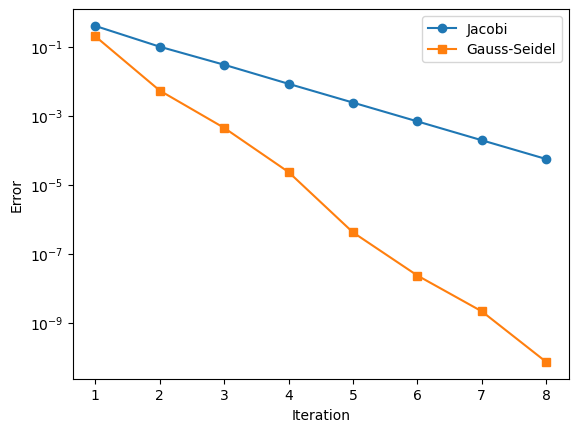

In [9]:
x_exact = np.array([1, 1, 1])
err_j, err_g = [], []

for k in range(1, 9):
    xj, _ = jacobi(A, b, tol=0, max_iter=k)         
    xg, _ = gauss_seidel(A, b, tol=0, max_iter=k)
    err_j.append(max(abs(xj - x_exact)))           
    err_g.append(max(abs(xg - x_exact)))

plt.semilogy(range(1, 9), err_j, "o-", label="Jacobi")
plt.semilogy(range(1, 9), err_g, "s-", label="Gauss-Seidel")
plt.xlabel("Iteration")
plt.ylabel("Error")
plt.legend()
plt.show()